In [166]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.special import gammaln  # for log(y!) = gammaln(y+1)
from scipy.optimize import minimize
from patsy import dmatrix
from itertools import product
from scipy.stats import poisson

np.random.seed(2)

TIME_COL = "in Lund C"
BIN_MINUTES = 5
MORNING_START = "05:00:00"
MORNING_END = "11:00:00"

#helper function
def minutes_to_time(minutes):
    hours = minutes // 60
    mins = minutes % 60
    return f"{hours:02d}:{mins:02d}"

def time_to_minutes(time_str):
    hours, minutes, seconds = map(int, time_str.split(":"))
    return hours * 60 + minutes

## Loading and Preparing the Data

In [2]:
csv_path = Path("skane/Lund_C_20261020_all_commuters.csv")

df = pd.read_csv(csv_path)
df = df.sample(frac=1, random_state=42).reset_index(drop=True) #Dataframe looks too simulated. Shuffling might help!

print(f"Rows: {len(df):,}")
print("\nColumns:")
print(df.columns.tolist())
print()
print(df["commute_type"].value_counts())

df.head()

Rows: 66,728

Columns:
['worker_id', 'sex', 'residential_municipality', 'workplace_municipality', 'origin_station', 'destination_station', 'desired_arrival', 'commute_type', 'train_to_take', 'waiting_time', 'in Lund C']

commute_type
arrive    39940
leave     26788
Name: count, dtype: int64


,worker_id,sex,residential_municipality,workplace_municipality,origin_station,destination_station,desired_arrival,commute_type,train_to_take,waiting_time,in Lund C
0,38517,kvinnor,Staffanstorp,Malmö,Lund C,Malmö C,08:32:00,leave,08:08:00,00:10:00,07:58:00
1,16618,män,Malmö,Lund,Malmö C,Lund C,08:45:00,arrive,08:41:00,00:00:00,08:41:00
2,48007,kvinnor,Malmö,Staffanstorp,Malmö C,Lund C,08:41:00,arrive,08:39:00,00:00:00,08:39:00
3,60462,kvinnor,Lund,Malmö,Lund C,Malmö C,08:31:00,leave,08:08:00,00:06:00,08:02:00
4,14816,män,Malmö,Lund,Malmö C,Lund C,08:31:00,arrive,08:26:00,00:00:00,08:26:00


## Preparing five minute station-flow counts

The `in Lund C` column gives the simulated station time for both commute directions. We count records in five-minute bins and keep arrivals and departures separate.

In [3]:
# Convert HH:MM:SS to minutes after midnight.
time_parsed = pd.to_datetime(df[TIME_COL], format="%H:%M:%S", errors="coerce")
df = df.loc[time_parsed.notna()].copy()
time_parsed = time_parsed.loc[df.index]

df["minutes_after_midnight"] = ( time_parsed.dt.hour * 60 + time_parsed.dt.minute + time_parsed.dt.second / 60 )

start_min = 5 * 60
end_min = 11 * 60
morning = df[df["minutes_after_midnight"].between(start_min, end_min, inclusive="left")].copy()

morning["minutes_after_midnight"]

0        478.0
1        521.0
2        519.0
3        482.0
4        506.0
         ...  
66723    496.0
66724    482.0
66725    496.0
66726    492.0
66727    506.0
Name: minutes_after_midnight, Length: 66728, dtype: float64

In [4]:
# Floor each event to its five-minute interval.
morning["bin_minute"] = (np.floor(morning["minutes_after_midnight"] / BIN_MINUTES) * BIN_MINUTES).astype(int)

# Include empty intervals so the time series is continuous.
all_bins = np.arange(start_min, end_min, BIN_MINUTES)
directions = ["arrive", "leave"]
counts = ( morning.groupby(["commute_type", "bin_minute"])
            .size()
            .rename("count")
            .reset_index())

grid = pd.MultiIndex.from_product( [directions, all_bins], names=["commute_type", "bin_minute"]).to_frame(index=False)
counts = grid.merge(counts, on=["commute_type", "bin_minute"], how="left")
counts["count"] = counts["count"].fillna(0).astype(int)
counts["time"] = counts["bin_minute"].apply(minutes_to_time)

print(f"Commuters in morning window: {len(morning):,}")
print(counts.groupby("commute_type")["count"].sum())
counts

Commuters in morning window: 66,728
commute_type
arrive    39940
leave     26788
Name: count, dtype: int64


,commute_type,bin_minute,count,time
0,arrive,300,0,05:00
1,arrive,305,0,05:05
2,arrive,310,0,05:10
3,arrive,315,0,05:15
4,arrive,320,0,05:20
...,...,...,...,...
139,leave,635,0,10:35
140,leave,640,0,10:40
141,leave,645,0,10:45
142,leave,650,0,10:50


C:\Users\krane\miniforge3\envs\statistics\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
C:\Users\krane\miniforge3\envs\statistics\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


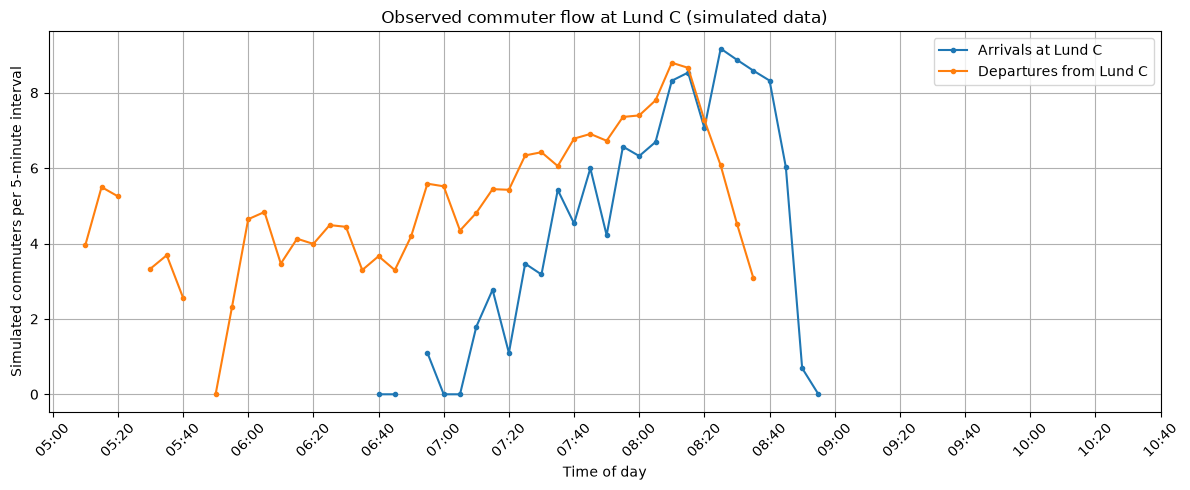

In [20]:
fig, ax = plt.subplots(figsize=(12, 5))

for direction, label in [("arrive", "Arrivals at Lund C"), ("leave", "Departures from Lund C")]:
    subset = counts[counts["commute_type"] == direction]
    ax.plot(subset["bin_minute"], np.log(subset["count"]), marker=".", linewidth=1.5, label=label)

ticks = np.arange(min(subset["bin_minute"]), max(subset["bin_minute"]) + 1, 20)
ax.set_xticks(ticks, [minutes_to_time(int(x)) for x in ticks])
ax.tick_params(axis="x", labelrotation=45)
ax.set_xlabel("Time of day")
ax.set_ylabel("Simulated commuters per 5-minute interval")
ax.set_title("Observed commuter flow at Lund C (simulated data)")
ax.grid()
ax.legend()
plt.tight_layout()
plt.show()

## Fitting a simple Poisson regression

The response is a count, so a Poisson regression is a reasonable first model. A spline lets the expected count rise and fall over the morning without forcing a straight-line trend.

In [159]:
def log_likelihood_poisson_glm(params, X, y):
    eta = X @ params
    lam = np.exp(np.clip(eta, -30, 30))

    log_lik = np.sum(y * eta - lam)
    return -log_lik

def build_model(X, y, df, degree):
    # Create the spline design matrix
    strinp = "bs(hour, df=" + str(df) +", degree="+ str(degree)+ ")- 1"
    modifiedX = np.asarray(dmatrix(strinp, data=X))

    # Initial parameter values
    initial_beta = np.zeros(modifiedX.shape[1])
    #initial_beta[0] = np.log(y.mean() + 1e-5)

    # Fit the Poisson regression
    result = minimize( log_likelihood_poisson_glm, initial_beta, args=(modifiedX, y), method="BFGS" )
    beta_hat = result.x

    return beta_hat

def predict(beta_hat, X, df, degree):
    strinp = "bs(hour, df=" + str(df) +", degree="+ str(degree)+ ")- 1"
    modifiedX = np.asarray(dmatrix(strinp, data=X))
    eta_hat = modifiedX @ beta_hat
    pred_mean = np.exp(eta_hat)
    return pred_mean

def kfold_validate(x, y, K, df, degree, random_seed= None, plot=False):
    "Divides the data into k folds"
    rng = np.random.default_rng(random_seed)
    idx = rng.permutation(len(y))

    x_randomized = x.iloc[idx].reset_index(drop=True)
    y_randomized = y.iloc[idx].reset_index(drop=True)

    assert len(x) % K == 0, "K must divide the number of observations equally."
    assert len(x) == len(y), "x and y must have the same number of observations."
    
    cutoff = len(x)//K
    
    idx  = list(range(len(x)))
    kMSEs = np.zeros((K),dtype=float)
    betas = []
    
    for k in range(K):
        val_idx   = idx[k*cutoff:(k+1)*cutoff]
        train_idx = idx[:k*cutoff] + idx[(k+1)*cutoff:]
        
        xval = x_randomized.iloc[val_idx]
        xtrain = x_randomized.iloc[train_idx]
        
        yval = y_randomized.iloc[val_idx]
        ytrain = y_randomized.iloc[train_idx]

        beta_hat = build_model(xtrain, ytrain, df, degree)
        y_pred = predict(beta_hat, xval, df, degree)
        kMSEs[k]= np.mean( ((yval - y_pred)**2) )
        betas.append(beta_hat)

    MSE = np.mean(kMSEs)
    return MSE, betas[np.argmin(kMSEs)]

In [160]:
counts["hour"] = counts["bin_minute"] / 60

#Experiment with both df and degrees
dofs = np.arange(1,10+1)
degrees = np.arange(1,10+1)

combinations = [(dof, degree)for dof, degree in product(dofs, degrees)if degree <= dof]

degMSEs = [[],[]] #arrive, leave
betas   = [[],[]] 

Xarrival = counts[counts["commute_type"] == "arrive"].copy()
yarrival = Xarrival["count"]
# yarrival = yarrival.apply(np.log) 
# yarrival.replace([np.inf, -np.inf], 0, inplace=True)

Xdeparture = counts[counts["commute_type"] == "leave"].copy()
ydeparture = Xdeparture["count"]
# ydeparture = ydeparture.apply(np.log)
# ydeparture.replace([np.inf, -np.inf], 0, inplace=True)

for df, degree in combinations:
    
    arr_mse, arr_betas = kfold_validate(Xarrival, yarrival, 3, df, degree)
    dep_mse, dep_betas = kfold_validate(Xdeparture, ydeparture, 3, df, degree)

    print(f"Validating (df,degree): ({df:2} , {degree:2})  arrive model MSE = {arr_mse:.5f},  departure model MSE = {dep_mse:.5f}", end="\r", flush = True)
    
    degMSEs[0].append(arr_mse)
    degMSEs[1].append(dep_mse)

    betas[0].append(arr_betas)
    betas[1].append(dep_betas)

Validating (df,degree): (10 , 10)  arrive model MSE = 2744106.88819,  departure model MSE = 1291256.30162ure model MSE = 2847793.37771504.000008171485354790845637422254036814383163439732930745274032881401856.00000

In [161]:


arr_idx, dep_idx = np.argmin(degMSEs[0]), np.argmin(degMSEs[1])
opt_df_arive , opt_degree_arive = combinations[arr_idx]
opt_df_leave , opt_degree_leave = combinations[dep_idx]
opt_arr_betas, opt_dep_betas = betas[0][arr_idx], betas[1][dep_idx] 

print("Cross Validation Error")
print("Arrive Model: ", degMSEs[0][arr_idx])
print("Leave Model: ", degMSEs[1][dep_idx])
print()
print("Optimal hyperparameters:" )
print("df arrive model ",opt_df_arive)
print("degree arrive model ",opt_degree_arive)
print("df leave model ",opt_df_leave)
print("degree leave model ",opt_degree_leave)

Cross Validation Error
Arrive Model:  878079.0963279982
Leave Model:  397278.9739657538

Optimal hyperparameters:
df arrive model  10
degree arrive model  9
df leave model  8
degree leave model  7


In [182]:
### Running this cell will change the model  if the optimal params above have been changed!

models_custom = {}
predictions_custom = []

for direction in ["arrive", "leave"]:

    d = counts[counts["commute_type"] == direction].copy()

    if direction == "arrive":
        df, degree = opt_df_arive , opt_degree_arive
        beta_hat = opt_arr_betas
    if direction == "leave":
        df, degree = opt_df_leave , opt_degree_leave
        beta_hat = opt_dep_betas
    
    # Create the spline design matrix
    strinp = "bs(hour, df=" + str(df) +", degree="+ str(degree)+ ") - 1"
    X = np.asarray(dmatrix(strinp, data=d))
    y = d["count"]
    # y = y.apply(np.log) 
    # y.replace([np.inf, -np.inf], 0, inplace=True)

    # # Initial parameter values
    # initial_beta = np.zeros(X.shape[1])
    # initial_beta[0] = np.log(y.mean() + 1e-5)

    # # Fit the Poisson regression
    # result = minimize( log_likelihood_poisson_glm, initial_beta, args=(X, y), method="BFGS" )
    # beta_hat = result.x

    models_custom[direction] = {"beta": beta_hat}

    #print(f"{direction.capitalize()} model converged: {result.success}")

    # Calculate predicted counts
    eta_hat = X @ beta_hat
    pred_mean = np.exp(eta_hat)
    lower, upper = poisson.interval(0.95, mu=pred_mean)
    yerr_lower =  lower 
    yerr_upper =  upper 
    
    # Approximate confidence intervals
    # cov_matrix = np.asarray(result.hess_inv)
    #se_linear = np.sqrt(np.clip(np.sum((X @ cov_matrix) * X, axis=1), 0, None))

    pred = d[["bin_minute", "time", "hour"]].copy()
    pred["observed"] = y
    pred["predicted"] = pred_mean
    pred["lower_95"] = lower
    pred["upper_95"] = upper
    pred["commute_type"] = direction

    predictions_custom.append(pred)

# Combine predictions for both directions
predictions_custom = pd.concat(predictions_custom, ignore_index=True)
predictions_custom.head()


,bin_minute,time,hour,observed,predicted,lower_95,upper_95,commute_type
0,300,05:00,5.000000,0,1.000000e+00,0.0,3.0,arrive
1,305,05:05,5.083333,0,9.706310e-179,0.0,0.0,arrive
2,310,05:10,5.166667,0,6.681195e-284,0.0,0.0,arrive
3,315,05:15,5.250000,0,0.000000e+00,0.0,0.0,arrive
4,320,05:20,5.333333,0,0.000000e+00,0.0,0.0,arrive


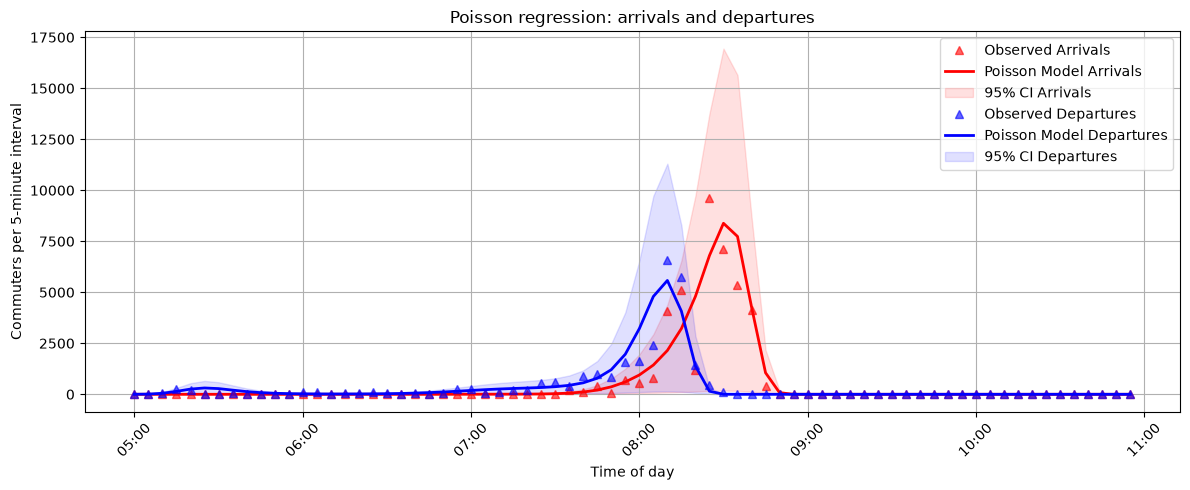

In [187]:
fig, ax = plt.subplots(figsize=(12, 5))

for direction, label, color in [("arrive", "Arrivals", 'red'), ("leave", "Departures", 'blue')]:
    pred = predictions_custom[predictions_custom["commute_type"] == direction]

    ax.plot(pred["hour"], pred["observed"], "^", alpha=0.6, label=f"Observed {label}", color=color)
    ax.plot(pred["hour"], pred["predicted"], linewidth=2, label=f"Poisson Model {label}", color=color)
    ax.fill_between( pred["hour"], pred["predicted"] - pred["lower_95"], pred["predicted"] + pred["upper_95"], alpha=0.12, label=f"95% CI {label}", color=color)
    
    ticks = np.arange(min(pred["hour"]), max(pred["hour"]) + 1, 1)
    ax.set_xticks(ticks, [minutes_to_time(int(x*60))[:5] for x in ticks])
    ax.tick_params(axis="x", labelrotation=45)

ax.set_xlabel("Time of day")
ax.set_ylabel("Commuters per 5-minute interval")
ax.set_title("Poisson regression: arrivals and departures")
ax.grid()
ax.legend()
plt.tight_layout()
plt.show()

## Identifying rush-hour peaks

We report both the busiest observed five-minute interval and the interval with the largest fitted mean. The model can smooth isolated spikes, so the two peak times may differ.

In [192]:

def peak_summary(frame, value_col):
    idx = frame[value_col].idxmax()
    row = frame.loc[idx]

    return {
        "peak_time": row["time"],
        "commuters_per_5min": round(float(row[value_col]), 1),
    }


rows = []

directions = ["arrive", "leave"]

for direction in directions:

    p = predictions_custom[
        predictions_custom["commute_type"] == direction
    ].copy()

    # Highest observed count
    observed_peak = peak_summary(p, "observed")

    # Highest predicted count from the Poisson model
    fitted_peak = peak_summary(p, "predicted")

    # Confidence interval at the fitted peak
    fitted_idx = p["predicted"].idxmax()
    fitted_row = p.loc[fitted_idx]

    rows.append({
        "direction": (
            "Arrivals at Lund C"
            if direction == "arrive"
            else "Departures from Lund C"
        ),
        "busiest_observed_interval": observed_peak["peak_time"],
        "observed_count": observed_peak["commuters_per_5min"],
        "highest_fitted_interval": fitted_peak["peak_time"],
        "fitted_mean_count": fitted_peak["commuters_per_5min"],
        "lower_95": round(float(fitted_row["lower_95"]), 1),
        "upper_95": round(float(fitted_row["upper_95"]), 1),
    })


peak_table = pd.DataFrame(rows)

peak_table


,direction,busiest_observed_interval,observed_count,highest_fitted_interval,fitted_mean_count,lower_95,upper_95
0,Arrivals at Lund C,08:25,9607.0,08:30,8382.0,8203.0,8562.0
1,Departures from Lund C,08:10,6607.0,08:10,5579.1,5433.0,5726.0
